In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np

In [3]:
import pandas as pd

#Data processing

path = '/content/drive/MyDrive/Data Analysis Project/Project 1/'
patients=pd.read_csv(path + 'patients.csv')
diagnoses = pd.read_csv(path + 'diagnoses.csv')
outcomes=pd.read_csv(path + 'outcomes.csv')
labs=pd.read_csv(path + 'labs.csv')

In [4]:
df = (patients
      .merge(diagnoses, on='DiagnosisID', how='left')
      .merge(outcomes, on='OutcomeID', how='left'))

df.head()

,PatientID,Name,Age,Gender,DiagnosisID,AdmissionDate,DischargeDate,OutcomeID,TreatmentCost,DiagnosisName,OutcomeName
0,1,Edward Montes,68,M,2,2025-03-22,2025-04-04,1,4443,Diabetes,Recovered
1,2,Jessica Zimmerman,81,M,2,2025-03-31,2025-04-02,2,4265,Diabetes,Complicated
2,3,Gina Alexander,58,M,6,2025-01-08,2025-03-13,1,4188,COPD,Recovered
3,4,Lori Green,44,F,3,2025-04-03,2025-04-05,1,9783,Heart Disease,Recovered
4,5,Jack Logan,72,F,9,2025-06-03,2025-06-04,1,5005,Kidney Disease,Recovered


In [5]:
df['AdmissionDate']=pd.to_datetime(df['AdmissionDate'])
df['DischargeDate']=pd. to_datetime(df['DischargeDate'])
df['Lengthofstay']=(df['DischargeDate']-df['AdmissionDate']).dt.days

In [6]:
df['OutcomeEncoded']=df['OutcomeName'].map({'Recovered':0,'Complicated':1,'Deceased':1})

In [7]:
df['HighRisk']=np.where((df['Age']>65)|(df['OutcomeName'].isin(['Complicated','Deceased'])),1,0)

In [8]:
abnormal_conditions = {
    'Blood Sugar': lambda x: x > 120,
    'Cholesterol': lambda x: x > 200,
    'Hemoglobin':  lambda x: x < 13
}

def count_abnormal_labs(patient_id):
    patient_labs = labs[labs['PatientID'] == patient_id]
    count = 0
    for test_name, condition in abnormal_conditions.items():
        test_results = patient_labs[patient_labs['TestName'] == test_name]
        count += test_results['Result'].apply(condition).sum()
    return count                      # aligned with "for", so it runs after the loop

df['AbnormalLabcount'] = df['PatientID'].apply(count_abnormal_labs)

In [9]:
#Model Training

features = df[['Age', 'Lengthofstay','TreatmentCost']]
target = df['OutcomeEncoded']

In [10]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size = 0.3, random_state=42)

In [11]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter = 500)
model.fit(X_train, y_train)

LogisticRegression(max_iter=500)

In [12]:
from sklearn.metrics import classification_report, confusion_matrix
y_pref = model. predict(X_test)
print("Classification Report: ")
print(classification_report(y_test, y_pref))

Classification Report: 
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        17
           1       0.72      1.00      0.83        43

    accuracy                           0.72        60
   macro avg       0.36      0.50      0.42        60
weighted avg       0.51      0.72      0.60        60



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


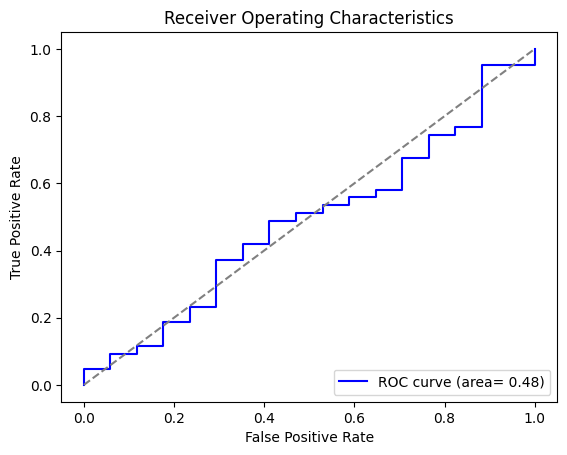

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

y_prod = model.predict_proba(X_test)[:,1]
fpr,tpr, thresholds = roc_curve(y_test, y_prod)
roc_auc =auc(fpr,tpr)

plt.figure()
plt.plot(fpr, tpr,color = 'Blue', label = f'ROC curve (area= {roc_auc:.2f})')
plt.plot([0,1],[0,1], color= 'gray', linestyle = '--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristics')
plt.legend(loc='lower right')
plt.show()

In [14]:
import joblib
joblib.dump(model, '/content/Risk_model1.pkl')

['/content/Risk_model1.pkl']

In [15]:
joblib.dump(model, path+'Risk_model1.pkl')

['/content/drive/MyDrive/Data Analysis Project/Project 1/Risk_model1.pkl']

In [16]:
!ls -la /content/Risk_model1.pkl

-rw-r--r-- 1 root root 1183 Oct 31 19:05 /content/Risk_model1.pkl


In [17]:
pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 54.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 73.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [27]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

model = joblib.load('Risk_model1.pkl')

st.title("Healthcare Risk Stratification App")

age = st.number_input("Age", min_value=0)
length_of_stay = st.number_input("Length of stay (days)", min_value=0)
treatment_cost = st.number_input("Treatment cost", min_value=0.0)

if st.button("Predict"):
    input_data = pd.DataFrame(
        [[age, length_of_stay, treatment_cost]],
        columns=['Age', 'Lengthofstay', 'TreatmentCost']
    )
    prediction = model.predict(input_data)[0]
    probability = model.predict_proba(input_data)[0][1]

    st.write(f"Risk Prediction: {'High Risk' if prediction == 1 else 'Low Risk'}")
    st.write(f"Risk Probability: {round(probability, 2)}")

Overwriting app.py


In [28]:
!streamlit run app.py &>/content/logs.txt &

In [29]:
!cat /content/logs.txt




2026-10-31 19:14:21.700 Uvicorn server started on :::8502


In [30]:
!curl ipv4.icanhazip.com

34.106.167.83


In [31]:
!cat /content/logs.txt
!ps aux | grep streamlit




2026-10-31 19:14:21.700 Uvicorn server started on :::8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://34.106.167.83:8502

root        4057  1.4  1.7 1600908 236176 ?      Sl   19:06   0:07 /usr/bin/python3 /usr/local/bin/streamlit run app.py
root        6072 30.2  0.5 451980 72412 ?        Sl   19:14   0:02 /usr/bin/python3 /usr/local/bin/streamlit run app.py
root        6118  0.0  0.0   7344  3552 ?        S    19:14   0:00 /bin/bash -c ps aux | grep streamlit
root        6120  0.0  0.0   6548  2328 ?        S    19:14   0:00 grep streamlit


In [32]:
!ls /content    # check that app.py and Risk_model1.pkl are listed
!nohup streamlit run app.py --server.port 8501 > /content/logs.txt 2>&1 &
import time; time.sleep(10)
!cat /content/logs.txt
!curl -s -o /dev/null -w "%{http_code}" http://localhost:8501

app.py	cf.txt	cloudflared  drive  logs.txt  Risk_model1.pkl  sample_data


2026-10-31 19:14:33.303 Port 8501 is not available
200

In [33]:
!nohup ./cloudflared tunnel --url http://localhost:8501 > /content/cf.txt 2>&1 &
import time; time.sleep(8)
!grep -o 'https://[a-z0-9-]*\.trycloudflare\.com' /content/cf.txt

https://employed-charge-does-mainland.trycloudflare.com
